In [1]:
import numpy as np
import pandas as pd
import torch

from PIL import Image
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/image_metadata.csv")

print(df.shape)

(4139, 6)


In [3]:
def get_color_histogram(image_path, bins=32):
    image = Image.open(image_path).convert("RGB")

    image_array = np.array(image)

    histograms = []

    for channel in range(3):
        histogram, _ = np.histogram(
            image_array[:, :, channel],
            bins=bins,
            range=(0, 256)
        )

        histograms.append(histogram)

    histogram = np.concatenate(histograms)

    histogram = histogram.astype(np.float32)

    # Normalize
    histogram = histogram / histogram.sum()

    return histogram

In [4]:
query_index = 100
query_path = df.iloc[query_index].path

histogram = get_color_histogram(query_path)

print(histogram.shape)
print(histogram[:10])
print("Sum:", histogram.sum())

(96,)
[0.01350985 0.01722446 0.02475342 0.02854384 0.02710747 0.02387165
 0.01890421 0.01582001 0.01540107 0.01553672]
Sum: 1.0


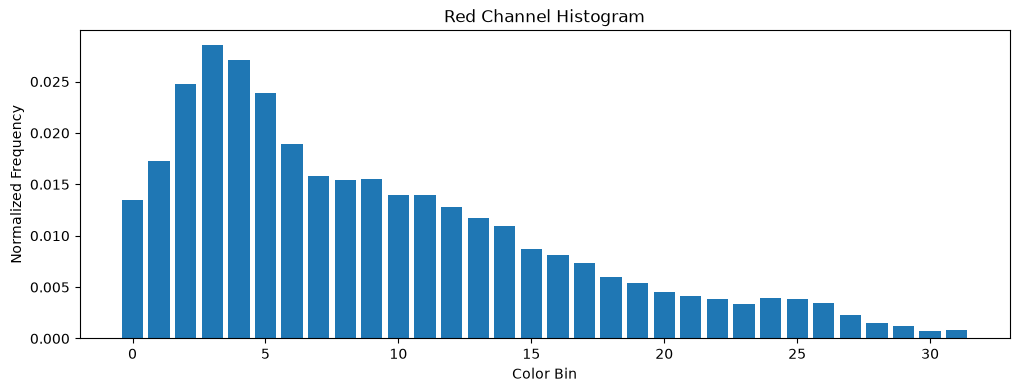

In [5]:
plt.figure(figsize=(12, 4))

plt.bar(range(32), histogram[:32])
plt.title("Red Channel Histogram")
plt.xlabel("Color Bin")
plt.ylabel("Normalized Frequency")

plt.show()

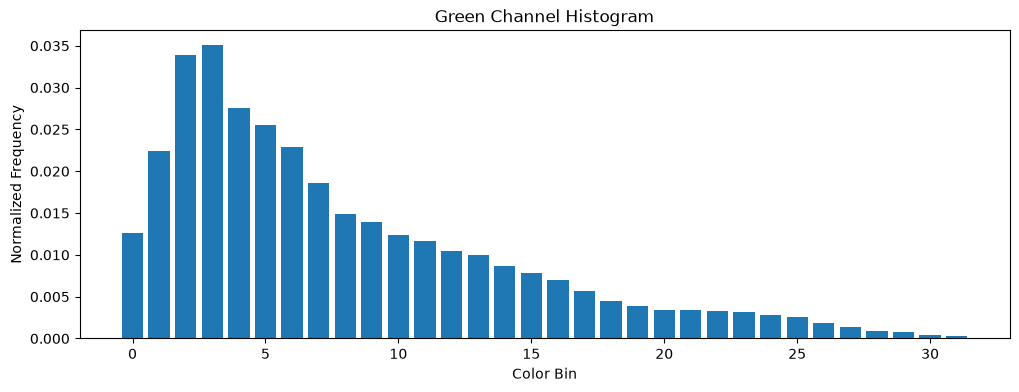

In [6]:
plt.figure(figsize=(12, 4))

plt.bar(range(32), histogram[32:64])
plt.title("Green Channel Histogram")
plt.xlabel("Color Bin")
plt.ylabel("Normalized Frequency")

plt.show()

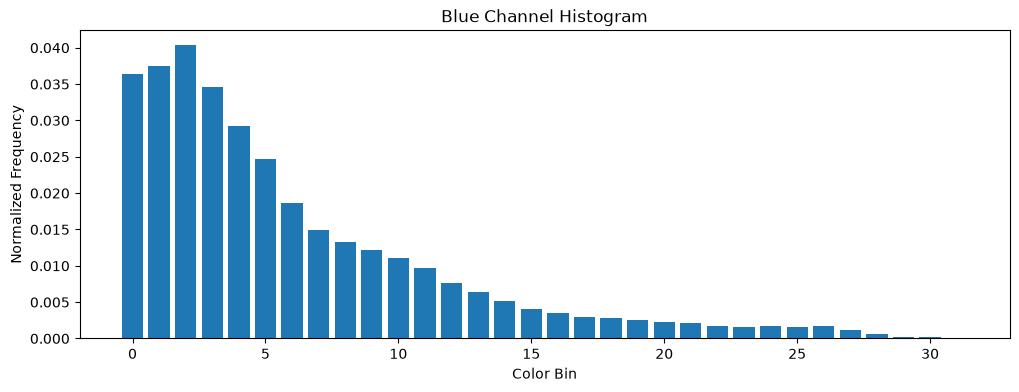

In [7]:
plt.figure(figsize=(12, 4))

plt.bar(range(32), histogram[64:96])
plt.title("Blue Channel Histogram")
plt.xlabel("Color Bin")
plt.ylabel("Normalized Frequency")

plt.show()

In [8]:
import torch.nn.functional as F

hist_a = torch.tensor(
    get_color_histogram(df.iloc[100].path)
)

hist_b = torch.tensor(
    get_color_histogram(df.iloc[101].path)
)

similarity = F.cosine_similarity(
    hist_a.unsqueeze(0),
    hist_b.unsqueeze(0)
)

print(similarity.item())

0.4236728250980377


In [9]:
def get_color_histograms_batch(image_paths, bins=32):
    histograms = []

    for image_path in image_paths:
        histogram = get_color_histogram(
            image_path,
            bins=bins
        )

        histograms.append(histogram)

    return torch.tensor(
        np.stack(histograms)
    )

In [10]:
test_paths = df["path"].iloc[:8].tolist()

test_histograms = get_color_histograms_batch(test_paths)

print(test_histograms.shape)

torch.Size([8, 96])


In [11]:
batch_size = 64

all_color_histograms = []

for start in range(0, len(df), batch_size):
    batch_paths = df["path"].iloc[
        start:start + batch_size
    ].tolist()

    batch_histograms = get_color_histograms_batch(
        batch_paths
    )

    all_color_histograms.append(batch_histograms)

    print(
        f"Processed "
        f"{min(start + batch_size, len(df))}/{len(df)}"
    )

Processed 64/4139
Processed 128/4139
Processed 192/4139
Processed 256/4139
Processed 320/4139
Processed 384/4139
Processed 448/4139
Processed 512/4139
Processed 576/4139
Processed 640/4139
Processed 704/4139
Processed 768/4139
Processed 832/4139
Processed 896/4139
Processed 960/4139
Processed 1024/4139
Processed 1088/4139
Processed 1152/4139
Processed 1216/4139
Processed 1280/4139
Processed 1344/4139
Processed 1408/4139
Processed 1472/4139
Processed 1536/4139
Processed 1600/4139
Processed 1664/4139
Processed 1728/4139
Processed 1792/4139
Processed 1856/4139
Processed 1920/4139
Processed 1984/4139
Processed 2048/4139
Processed 2112/4139
Processed 2176/4139
Processed 2240/4139
Processed 2304/4139
Processed 2368/4139
Processed 2432/4139
Processed 2496/4139
Processed 2560/4139
Processed 2624/4139
Processed 2688/4139
Processed 2752/4139
Processed 2816/4139
Processed 2880/4139
Processed 2944/4139
Processed 3008/4139
Processed 3072/4139
Processed 3136/4139
Processed 3200/4139
Processed 3264/4

In [12]:
all_color_histograms = torch.cat(
    all_color_histograms,
    dim=0
)

print(all_color_histograms.shape)

torch.Size([4139, 96])


In [13]:
all_color_histograms = (
    all_color_histograms /
    all_color_histograms.norm(
        dim=1,
        keepdim=True
    )
)

In [14]:
print(all_color_histograms[0].norm())

tensor(1.)


In [15]:
import os

os.makedirs("../data/embeddings", exist_ok=True)

torch.save(
    all_color_histograms,
    "../data/embeddings/color_histograms.pt"
)

In [16]:
def retrieve_similar_color_images(
    query_path,
    embeddings,
    df,
    top_k=5
):
    query_histogram = torch.tensor(
        get_color_histogram(query_path)
    )

    query_histogram = (
        query_histogram /
        query_histogram.norm()
    )

    similarities = embeddings @ query_histogram

    # Don't return the query image itself
    matches = df.index[
        df["path"] == query_path
    ].tolist()

    if matches:
        similarities[matches[0]] = -1

    top_scores, top_indices = torch.topk(
        similarities,
        k=top_k
    )

    return top_indices, top_scores

In [17]:
color_embeddings = torch.load(
    "../data/embeddings/color_histograms.pt"
)

In [18]:
query_index = 100
query_path = df.iloc[query_index].path

In [19]:
color_indices, color_scores = retrieve_similar_color_images(
    query_path,
    color_embeddings,
    df,
    top_k=5
)

In [20]:
for rank, (index, score) in enumerate(
    zip(color_indices, color_scores),
    start=1
):
    row = df.iloc[index.item()]

    print(
        f"{rank}. {row.room} | {row.style} | "
        f"similarity={score.item():.4f}"
    )

1. living_room | industrial | similarity=0.9823
2. living_room | industrial | similarity=0.9806
3. living_room | industrial | similarity=0.9755
4. bedroom | industrial | similarity=0.9754
5. bedroom | industrial | similarity=0.9741


In [21]:
def show_image(image_path, title=None):
    image = Image.open(image_path)

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")

    if title:
        plt.title(title)

    plt.show()

1. living_room | industrial | similarity=0.9823


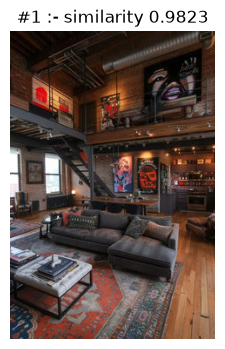

2. living_room | industrial | similarity=0.9806


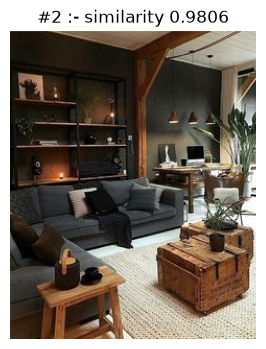

3. living_room | industrial | similarity=0.9755


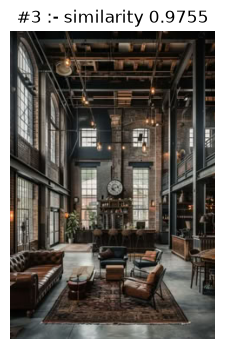

4. bedroom | industrial | similarity=0.9754


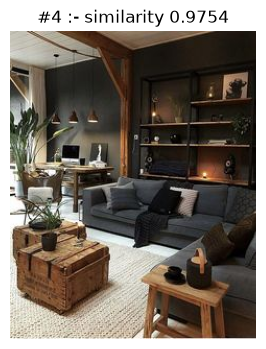

5. bedroom | industrial | similarity=0.9741


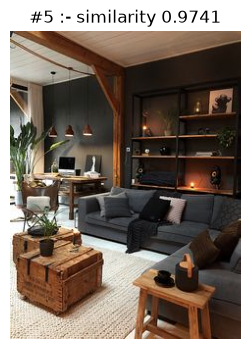

In [22]:
for rank, (index, score) in enumerate(
    zip(color_indices, color_scores),
    start=1
):
    row = df.iloc[index.item()]

    print(
        f"{rank}. {row.room} | {row.style} | "
        f"similarity={score.item():.4f}"
    )

    show_image(
        row.path,
        f"#{rank} :- similarity {score.item():.4f}"
    )